# 12 · The predictors: what they are, why they are used, and what each adds

The land-use forecast ranks where each change is likely from twelve predictors (elevation,
population, rainfall, roads, …). In land-change models these are *location factors*: they help place change, and are judged by how well the forecast places it (Verburg et al. 2004). 

This notebook checks them, in three steps:

1. **What each predictor is and why it is used**, with the data source and a reference from the
   land-change literature where one exists; and the labels of the methodology document (§6.2),
   seven of which are attached to the wrong layer (notebook 06).
2. **Drop-one test:** the improved method retrained without each predictor in turn. A predictor
   that carries information costs accuracy when it is left out.
3. **Guinea-specific candidates** the set does not cover, with public data: mining areas (Maus et
   al. 2022) and fire (MODIS burned area; Giglio et al. 2018).

**Same design and rule as notebooks 06–09.** The improved method (notebook 09, section 4): random
forest with contagion features, logistic regression and the copy of FLUS's network, averaged. Every
part is retrained with the same change (`scripts/predictor_tests.py`). Seed 42; the spread across
seeds of the improved method (three seeds) is the threshold for a real difference (Bouthillier et
al. 2021). A candidate is chosen on 2023→2024 and tested once on 2024→2025, and must pass the
flip-back check.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import esri_methods as E
import predictor_tests as P
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
PH = ("validation", "test")
v, t = "FoM % 2023→2024", "FoM % 2024→2025"
cv, ct = "Check: new-change FoM % 2023→2024", "Check: new-change FoM % 2024→2025"
prof = E.grid(); g = H.guinea_mask(prof)


def kinds(tag, ph):
    """All-change FoM ("FoM") and the flip-back check ("new") of a saved forecast."""
    _, ts, tf = E.phase_years(ph)
    sim = H.read_tif(E.RUNS / tag / ph / "allocation" / "Expander-only" / "predicted_land_cover.tif")[0]
    return E.change_kind_scores(ts, E.esri_cached(tf), sim, g)


def run(tag, **options):
    """A variant of the improved method on both years (cached; scripts/run_predictor_tests.py runs them all)."""
    return {ph: (P.improved_variant(tag, ph, **options), kinds(tag, ph))[1] for ph in PH}


half_range = lambda xs: (max(xs) - min(xs)) / 2
seeds = {ph: [kinds(tag, ph) for tag in ("improved_flus_copy", "improved_flus_copy_seed1", "improved_flus_copy_seed2")] for ph in PH}
# the larger of the two years' spreads, for both years (2023->2024 alone is only ±0.01)
spread = dict.fromkeys(PH, max(half_range([x["FoM"] for x in seeds[ph]]) for ph in PH))
spread_new = dict.fromkeys(PH, max(half_range([x["new"]["FoM"] for x in seeds[ph]]) for ph in PH))
full = run("pred_full")
print("Improved method, seed 42, rebuilt here: FoM %.2f%% (2023→2024), %.2f%% (2024→2025), as in notebook 09; "
      "spread across seeds ±%.2f" % (full["validation"]["FoM"], full["test"]["FoM"], spread["test"]))

Improved method, seed 42, rebuilt here: FoM 18.55% (2023→2024), 20.37% (2024→2025), as in notebook 09; spread across seeds ±0.04


## 1 · The predictors

From the deployed module's configuration (`landuse_tool/config.py`) and the files it fetched.
Dated layers are taken at the start of each forecast interval (notebook 06). *In other models*: the
same factor in the driving-factor table of PLUS (Liang et al. 2021, Table 3) or in the models named.

| # | Predictor | Data | Family | In other land-change models |
|---:|---|---|---|---|
| 1 | Elevation | SRTM 30 m (USGS/SRTMGL1_003) | Terrain | PLUS (DEM; Liang et al. 2021); CLUE-S location factors (Verburg et al. 2002) |
| 2 | Population density | WorldPop 100 m, 2020 | People | PLUS (population; Liang et al. 2021); a main driver of agricultural and settlement change (Veldkamp & Lambin 2001) |
| 3 | Precipitation | CHIRPS, annual total, ≈5.5 km, dated | Climate | PLUS (annual precipitation; Liang et al. 2021) |
| 4 | Soil moisture | ERA5-Land top layer, annual mean, ≈11 km, dated | Soil and water | PLUS uses soil type (Liang et al. 2021); soil moisture stands in for it here |
| 5 | Above-ground biomass | NASA ORNL biomass carbon density, 300 m, ≈2010 | Vegetation state | No standard reference as a land-change predictor; the module keeps it for its scenario functions |
| 6 | NDVI | MODIS MOD13Q1, annual mean, 250 m, dated | Vegetation state | No standard reference; the module added it to separate crops from similar classes |
| 7 | Slope | From the elevation | Terrain | PLUS (slope; Liang et al. 2021); CLUE-S (Verburg et al. 2002) |
| 8 | Aspect | From the elevation | Terrain | Not in PLUS's table; the module's own note says its effect is usually weak |
| 9 | Distance to roads | OpenStreetMap roads | Access | PLUS (proximity to roads; Liang et al. 2021); roads lead land conversion in the tropics (Geist & Lambin 2002) |
| 10 | Distance to waterways | OpenStreetMap rivers and water | Access, water | PLUS (proximity to open water; Liang et al. 2021) |
| 11 | Points of interest (density) | OpenStreetMap amenities | Settlements, services | PLUS uses proximity to government offices, from points of interest (Liang et al. 2021); mostly in urban models |
| 12 | Protected areas | WDPA polygons, inside or outside | Policy | Protected areas in Dinamica EGO's simulations of the Amazon (Soares-Filho et al. 2006) |

Families that are standard in the literature are all covered: terrain, climate, soil, people,
access and policy (Verburg et al. 2004). Two predictors describe the current vegetation (biomass,
NDVI) rather than a location factor, and aspect has no clear use; the drop-one test below shows
what each adds.

### The labels in the methodology document (§6.2)

The deployed notebook stacked the layers in one order and labelled them in another (notebook 06,
section 1). Positions 2–8 carry the wrong names, so the predictor importance ranking published in
§6.2 is misread for those seven.

In [2]:
labels = pd.read_csv(H.SUMMARY / "06_predictor_labels.csv")
H.show(labels)

Position,Label used in the document,Layer actually there,Correct?
1,Elevation,Elevation,yes
2,Slope,Population density,NO
3,Aspect,Precipitation,NO
4,Population Density,Soil moisture,NO
5,Precipitation,AGB,NO
6,Soil Moisture,NDVI,NO
7,AGB,Slope,NO
8,NDVI,Aspect,NO
9,Roads (distance),Roads (distance),yes
10,Waterways (distance),Waterways (distance),yes


**For the methodology document:** rename positions 2–8 of the importance ranking as in the
column *Layer actually there* (for example, the importance listed for "Slope" belongs to population
density). Importance also says which inputs a model relies on, not what causes change; with
correlated inputs, random-forest importance is biased towards some of them (Strobl et al. 2007).
The drop-one test below is the more direct measure.

## 2 · Drop-one test

In [3]:
drop = {name: run(f"pred_drop_{i:02d}", drop=(name,)) for i, name in enumerate(E.PREDICTORS, 1)}


def effect(r):
    lower = [r["Δ " + v] < -spread["validation"], r["Δ " + t] < -spread["test"]]
    higher = [r["Δ " + v] > spread["validation"], r["Δ " + t] > spread["test"]]
    if all(lower):
        return "needed: leaving it out costs accuracy in both years"
    if all(higher):
        return "better without it, in both years"
    if any(lower) and not any(higher):
        return "small: costs accuracy in one year"
    return "no clear effect"


rows = pd.DataFrame([{"Predictor left out": name,
                      v: d["validation"]["FoM"], "Δ " + v: d["validation"]["FoM"] - full["validation"]["FoM"],
                      t: d["test"]["FoM"], "Δ " + t: d["test"]["FoM"] - full["test"]["FoM"],
                      "Δ " + ct: d["test"]["new"]["FoM"] - full["test"]["new"]["FoM"]} for name, d in drop.items()])
rows["Effect"] = rows.apply(effect, axis=1)
rows = rows.sort_values("Δ " + v).reset_index(drop=True)
rows.to_csv(H.SUMMARY / "12_drop_one.csv", index=False)
print(f"All twelve (seed 42): {full['validation']['FoM']:.2f}% / {full['test']['FoM']:.2f}%. "
      f"A difference counts if larger than ±{spread['test']:.2f}.")
H.show(rows)

All twelve (seed 42): 18.55% / 20.37%. A difference counts if larger than ±0.04.


Predictor left out,FoM % 2023→2024,Δ FoM % 2023→2024,FoM % 2024→2025,Δ FoM % 2024→2025,Δ Check: new-change FoM % 2024→2025,Effect
NDVI,14.37,-4.18,16.71,-3.67,-2.13,needed: leaving it out costs accuracy in both years
Precipitation,18.38,-0.16,20.27,-0.11,0.04,needed: leaving it out costs accuracy in both years
AGB,18.48,-0.07,19.88,-0.49,0.04,needed: leaving it out costs accuracy in both years
Population density,18.49,-0.05,20.26,-0.12,-0.04,needed: leaving it out costs accuracy in both years
Roads (distance),18.52,-0.02,20.29,-0.08,-0.02,small: costs accuracy in one year
Slope,18.53,-0.02,20.09,-0.28,-0.19,small: costs accuracy in one year
Waterways (distance),18.56,0.01,20.35,-0.02,-0.04,no clear effect
Elevation,18.56,0.01,20.42,0.05,0.25,no clear effect
Aspect,18.57,0.03,20.37,-0.01,0.04,no clear effect
POI (density),18.58,0.03,20.35,-0.03,-0.03,no clear effect


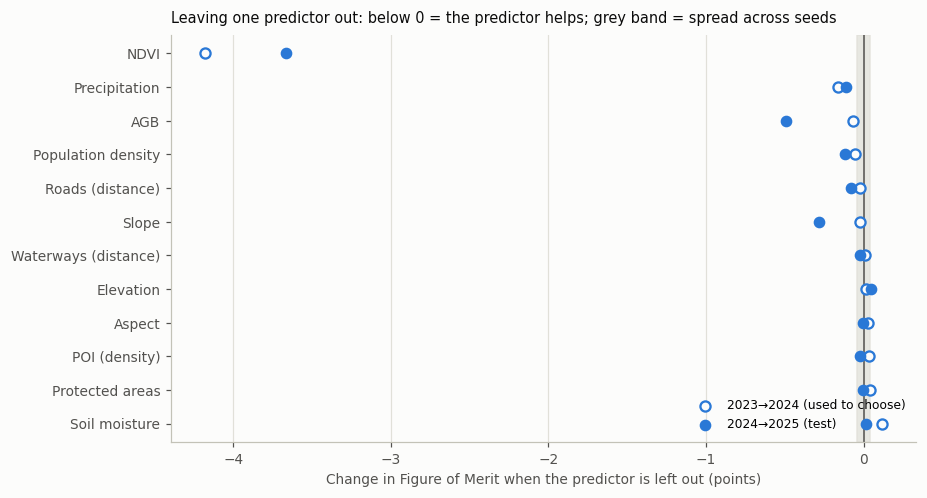

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
H.style_axes(ax)
y = np.arange(len(rows))[::-1]
for ph, col, style in (("validation", "Δ " + v, dict(facecolor=H.SURFACE, edgecolor=H.SERIES[0], lw=1.5)),
                       ("test", "Δ " + t, dict(color=H.SERIES[0]))):
    ax.axvspan(-spread[ph], spread[ph], color=H.GRID, alpha=0.6 if ph == "test" else 0.35, zorder=0)
    ax.scatter(rows[col], y, s=44, zorder=3, label="2023→2024 (used to choose)" if ph == "validation" else "2024→2025 (test)", **style)
ax.axvline(0, color=H.INK_2, lw=1)
ax.set_yticks(y, rows["Predictor left out"])
ax.set_xlabel("Change in Figure of Merit when the predictor is left out (points)", color=H.INK_2)
ax.set_title("Leaving one predictor out: below 0 = the predictor helps; grey band = spread across seeds",
             loc="left", fontsize=9.5, color=H.INK, pad=8)
ax.legend(loc="lower right", frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

**Reading:**

* **NDVI carries most of the information.** Without it the Figure of Merit falls by about 4 points in
  both years (18.55% → 14.37%, 20.37% → 16.71%), and the flip-back check falls too (new-change FoM
  −2.1 points on 2024→2025), so it helps find genuinely new change, not only flicker. It is dated to
  the start of each interval, so it is known when the forecast is made. Most of Esri's change is
  between trees and rangeland (notebook 06), and a pixel's greenness shows how close it is to that
  boundary.
* **Three more are needed in both years, by small margins:** precipitation (−0.16 and −0.11 points),
  above-ground biomass (−0.07 and −0.49) and population density (−0.05 and −0.12). **Slope and
  distance to roads** cost accuracy on 2024→2025 only (−0.28 and −0.08).
* **Six show no clear effect one at a time:** elevation, aspect, soil moisture, distance to
  waterways, points of interest and protected areas.
* The two predictors without a standard land-change reference, NDVI and biomass, are among those
  that carry the most: they describe the current state of the vegetation, which on Esri's maps
  decides much of the next year's change.

### The six with no clear effect, left out together

One at a time, leaving out a predictor that another one partly repeats changes little. Left out
together, they could still matter.

In [5]:
SIX = ("Elevation", "Aspect", "Soil moisture", "Waterways (distance)", "POI (density)", "Protected areas")
assert set(SIX) == set(rows.loc[rows["Effect"] == "no clear effect", "Predictor left out"])
six = run("pred_drop_six", drop=SIX)
together = pd.DataFrame([{"Configuration": name, v: d["validation"]["FoM"], t: d["test"]["FoM"],
                          cv: d["validation"]["new"]["FoM"], ct: d["test"]["new"]["FoM"]}
                         for name, d in {"All twelve predictors (seed 42)": full, "Without the six (six predictors)": six}.items()])
together.to_csv(H.SUMMARY / "12_without_six.csv", index=False)
H.show(together)

Configuration,FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025
All twelve predictors (seed 42),18.55,20.37,9.94,7.96
Without the six (six predictors),19.27,20.17,10.14,8.00


**Reading:**

* **Leaving the six out together does not pass the rule.** It gains on 2023→2024 (19.27% against
  18.55%) and passes the flip-back check (10.14% against 9.94%), but loses on 2024→2025 (20.17%
  against 20.37%, beyond the ±0.04 spread). Together they carry some information that each one
  alone does not show, and the gain on 2023→2024 did not hold.
* **So all twelve predictors stay.** None makes the forecast worse in both years, and removing the
  six would not simplify the forecast without a cost.

## 3 · Guinea-specific candidates

Two land-change processes in Guinea that none of the twelve predictors describes directly, tested
with the public data available now:

| Candidate | Why | Data | Layers (known at the forecast start) |
|---|---|---|---|
| **Mining** | Bauxite around Boké and Fria, gold in Upper Guinea (large-scale and artisanal); mining clears land and drives change around it (Sonter et al. 2017) | Global mining areas mapped from 2019 Sentinel-2 images: 128 areas, 231 km² in Guinea (Maus et al. 2022) | Distance to the nearest mining area (log of km) |
| **Fire** | Savanna fire is yearly in Guinea's savannas; cropland expansion changes where fire occurs (Andela & van der Werf 2014) | MODIS MCD64A1 burned area, 500 m (Giglio et al. 2018); 12–16% of Guinea burns each year | Burned in the start year; share of the last five years burned |

Each is added to all three parts of the improved method. Shifting cultivation, the third gap, has
no public map for Guinea.

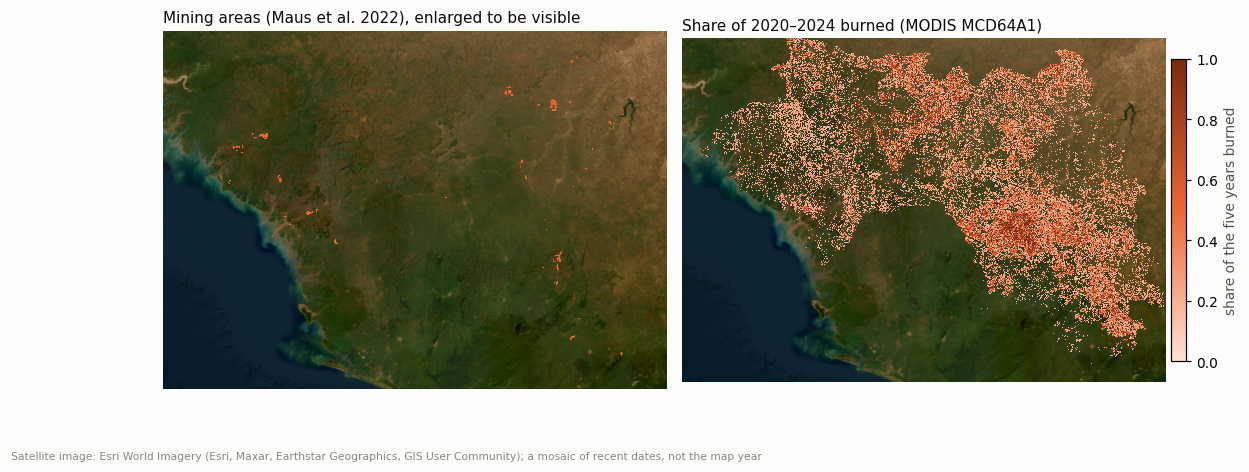

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"wspace": 0.03})
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import binary_dilation
mines = binary_dilation(np.expm1(P.mining_distance()) == 0, iterations=3) & g
fire5 = np.mean([P.burned(y) for y in range(2020, 2025)], axis=0)
H.plot_satellite(axes[0], prof, title="Mining areas (Maus et al. 2022), enlarged to be visible")
axes[0].imshow(np.ma.masked_where(~mines, mines), cmap=LinearSegmentedColormap.from_list("m", [H.SERIES[1], H.SERIES[1]]),
               interpolation="nearest")
H.plot_satellite(axes[1], prof, title="Share of 2020–2024 burned (MODIS MCD64A1)")
im = axes[1].imshow(np.ma.masked_where(~g | (fire5 == 0), fire5), vmin=0, vmax=1, interpolation="nearest",
                    cmap=LinearSegmentedColormap.from_list("f", ["#fde3d3", H.SERIES[1], "#7a2a0b"]))
fig.colorbar(im, ax=axes[1], fraction=0.03, pad=0.01).set_label("share of the five years burned", color=H.INK_2)
H.satellite_credit(fig, 0.02)
plt.show()

In [7]:
CANDIDATES = {"+ mining (distance to mining areas)": ("pred_add_mining", P.mining_layers),
              "+ fire (burned area)": ("pred_add_fire", P.fire_layers)}
cand = {name: run(tag, extra=layers) for name, (tag, layers) in CANDIDATES.items()}


def rule(d):
    gain_v, gain_t = d["validation"]["FoM"] - full["validation"]["FoM"], d["test"]["FoM"] - full["test"]["FoM"]
    if gain_v <= spread["validation"]:
        return "not chosen: no gain on 2023→2024"
    if d["validation"]["new"]["FoM"] < full["validation"]["new"]["FoM"] - spread_new["validation"]:
        return "not chosen: fails the flip-back check"
    return "improves" if gain_t > spread["test"] else "chosen, but no gain on 2024→2025"


table = pd.DataFrame([{"Configuration": "Improved method, twelve predictors (seed 42)", v: full["validation"]["FoM"],
                       t: full["test"]["FoM"], cv: full["validation"]["new"]["FoM"], ct: full["test"]["new"]["FoM"],
                       "Against the rule": "reference"}] +
                     [{"Configuration": name, v: d["validation"]["FoM"], t: d["test"]["FoM"], cv: d["validation"]["new"]["FoM"],
                       ct: d["test"]["new"]["FoM"], "Against the rule": rule(d)} for name, d in cand.items()])
table.to_csv(H.SUMMARY / "12_candidates.csv", index=False)
H.show(table)

Configuration,FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025,Against the rule
"Improved method, twelve predictors (seed 42)",18.55,20.37,9.94,7.96,reference
+ mining (distance to mining areas),18.52,20.39,10.01,8.02,not chosen: no gain on 2023→2024
+ fire (burned area),18.46,20.48,9.93,8.00,not chosen: no gain on 2023→2024


**Reading:**

* **Neither candidate is chosen.** Mining: 18.52% on 2023→2024 against 18.55%, no gain (2024→2025:
  20.39%). Fire: 18.46% against 18.55%, lower, then 20.48% on 2024→2025. A gain on the test year
  alone does not count: the choice is made on 2023→2024.
* **Mining areas are small at the scale of the national forecast:** 231 km² mapped in 2019, against
  about 31,700 km² of change in one year (507,539 pixels of 6.25 ha), most of it between trees and
  rangeland. The module's mining scenario remains useful for questions about mining; as a predictor
  of the national forecast, distance to mines adds nothing measurable.
* **Fire** probably repeats what NDVI and the class map already show (savanna burns, dense forest
  rarely does), so it adds little.
* **Data limits:** the mining areas are those of 2019 (newer artisanal sites are missed), and MODIS
  burned area at 500 m misses small fires. A national mining cadastre or newer mine maps could be
  tested the same way when available.

## 4 · What this means

* **The predictor set is adequate for the land-use forecast.** It covers the standard families of
  the land-change literature (terrain, climate, soil, people, access, policy; Verburg et al. 2004),
  and the drop-one test shows which inputs the forecast relies on: NDVI above all, then rainfall,
  biomass and population, then slope and roads.
* **No change to the set is needed.** No predictor makes the forecast worse, leaving out the six
  with no clear effect costs accuracy on the test year, and neither Guinea-specific candidate
  (mining, fire) improves it.
* **For the methodology document:** correct the seven predictor labels (section 1), and present the
  drop-one table as the inputs the forecast relies on, not as causes of land change.
* **Causes of change**, especially of forest loss, are the deforestation module's question, with its
  own driver assessment.

### References

* Andela, N., van der Werf, G.R. (2014). Recent trends in African fires driven by cropland expansion
  and El Niño to La Niña transition. *Nature Climate Change* 4(9), 791–795.
* Bouthillier, X., et al. (2021). Accounting for variance in machine learning benchmarks.
  *Proceedings of Machine Learning and Systems* 3.
* Geist, H.J., Lambin, E.F. (2002). Proximate causes and underlying driving forces of tropical
  deforestation. *BioScience* 52(2), 143–150.
* Giglio, L., Boschetti, L., Roy, D.P., Humber, M.L., Justice, C.O. (2018). The Collection 6 MODIS
  burned area mapping algorithm and product. *Remote Sensing of Environment* 217, 72–85.
* Liang, X., Guan, Q., Clarke, K.C., Liu, S., Wang, B., Yao, Y. (2021). Understanding the drivers of
  sustainable land expansion using a patch-generating land use simulation (PLUS) model: a case study
  in Wuhan, China. *Computers, Environment and Urban Systems* 85, 101569.
* Maus, V., Giljum, S., da Silva, D.M., et al. (2022). An update on global mining land use.
  *Scientific Data* 9, 433. Data: doi:10.1594/PANGAEA.942325.
* Soares-Filho, B.S., Nepstad, D.C., Curran, L.M., et al. (2006). Modelling conservation in the
  Amazon basin. *Nature* 440, 520–523.
* Sonter, L.J., Herrera, D., Barrett, D.J., et al. (2017). Mining drives extensive deforestation in
  the Brazilian Amazon. *Nature Communications* 8, 1013.
* Strobl, C., Boulesteix, A.-L., Zeileis, A., Hothorn, T. (2007). Bias in random forest variable
  importance measures: illustrations, sources and a solution. *BMC Bioinformatics* 8, 25.
* Veldkamp, A., Lambin, E.F. (2001). Predicting land-use change. *Agriculture, Ecosystems &
  Environment* 85, 1–6.
* Verburg, P.H., Soepboer, W., Veldkamp, A., et al. (2002). Modeling the spatial dynamics of
  regional land use: the CLUE-S model. *Environmental Management* 30(3), 391–405.
* Verburg, P.H., Schot, P.P., Dijst, M.J., Veldkamp, A. (2004). Land use change modelling: current
  practice and research priorities. *GeoJournal* 61, 309–324.